### Module and pack scaling

I start with cell capacity fade and estimate usable capacity for an illustrative pack. I use the four-year aging study to motivate checking cell-model predictions against module tests. Reference paper: Cell-level versus module-level degradation of Li-ion batteries for grid-scale storage: A four-year parallel aging experiment and empirical capacity-fade analysis

In [12]:
from pathlib import Path
import pandas as pd
from pathlib import Path
import sys
from IPython.display import display
from module_pack_scaling import analyze, save_plots
from IPython.display import Image

In [10]:
cwd = Path.cwd()
project_root = next(
    folder
    for folder in (cwd, *cwd.parents)
    if (folder / "T1_data_engineering_preprocessing").is_dir()
)

raw_folder = project_root / "data" / "raw"

run_ids = [
    "LR1865SZ_cycles201217_001_2",
    "LR1865SZ_cycles201214_002_4",
]

In [ ]:
task5 = project_root / "T5_module_pack_scaling"

if task5.name != "T5_module_pack_scaling":
    task5 = task5 / "T5_module_pack_scaling"
sys.path.insert(0, str(task5))

summary = project_root / "data" / "processed" / "cycle_summary.csv"
if not summary.is_file():
    print("Demo mode: using an illustrative cell fade rate (0.004 per cycle).")
    summary = None

calibration, traces, scenarios, timing = analyze(summary)

#### Cell calibration
I fit an exponential fade rate to each eligible run using cycles 2–80. I use the median rate as the pack baseline.

In [2]:
display(calibration.round(6))

,Cell run,Fade rate per cycle
0,LR1865SZ_cycles201214_002_4,0.014007
1,LR1865SZ_cycles201217_001_2,0.020669


**My assumptions**
| Item | What I assume |
|---|---|
| Pack layout | Four 8S4P modules in series, with 128 cells rated at 2.5 Ah each. |
| Cell variation | I sample initial capacity and fade rate with 3% and 15% standard deviations before clipping, using a fixed random seed. |
| Temperature | I impose a 25–35 °C gradient and multiply the fade rate by 1.5 for every 10 °C increase. |
| Balancing | I reduce usable group charge by 0.5–4% to represent residual SOC mismatch. |
| Capacity | I add capacity within each parallel group. The lowest usable group capacity limits the module, and the lowest module capacity limits the pack. |

I fit the baseline fade to the cell data and choose the other inputs for the scenario.

In [3]:
display(scenarios.round(3))

,Scenario,Initial usable pack Ah,Final usable pack Ah,Final retention vs own start (%),Module 1 final Ah,Module 2 final Ah,Module 3 final Ah,Module 4 final Ah
0,Uniform cells,10.000,1.766,17.661,1.766,1.766,1.766,1.766
1,+ Cell variation,9.727,1.234,12.687,1.234,1.523,1.518,1.314
2,+ Temperature gradient,9.727,0.718,7.379,1.091,0.958,0.901,0.718
3,+ Residual SOC mismatch,9.426,0.689,7.311,1.083,0.937,0.874,0.689


**Accuracy and scalability**</br>
I compare a pack-average model, a model with one representative cell per parallel group, and a model that tracks every cell. I use the cell-resolved result as the reference for the error calculation.

In [4]:
display(timing.round(5))

,Resolution,Median simulation time (ms),MAE vs cell-resolved model (Ah),Final pack capacity (Ah)
0,Pack-average cell,0.0113,0.63443,1.16386
1,One representative cell per parallel group,0.0557,0.04116,0.63622
2,Cell-resolved reference,0.1658,0.00000,0.68909


**Pack capacity and runtime plots**</br>
I add cell variation, temperature gradients, and SOC mismatch one at a time. Each curve includes the effects added before it.

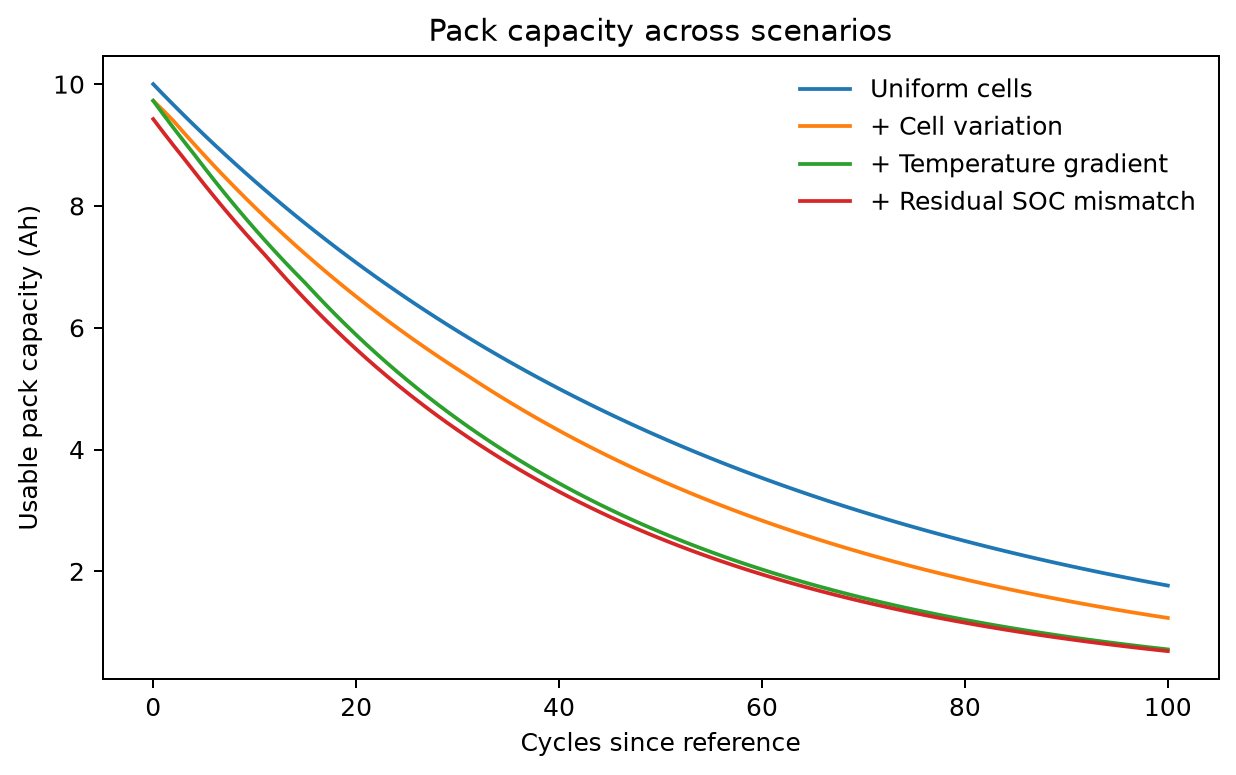

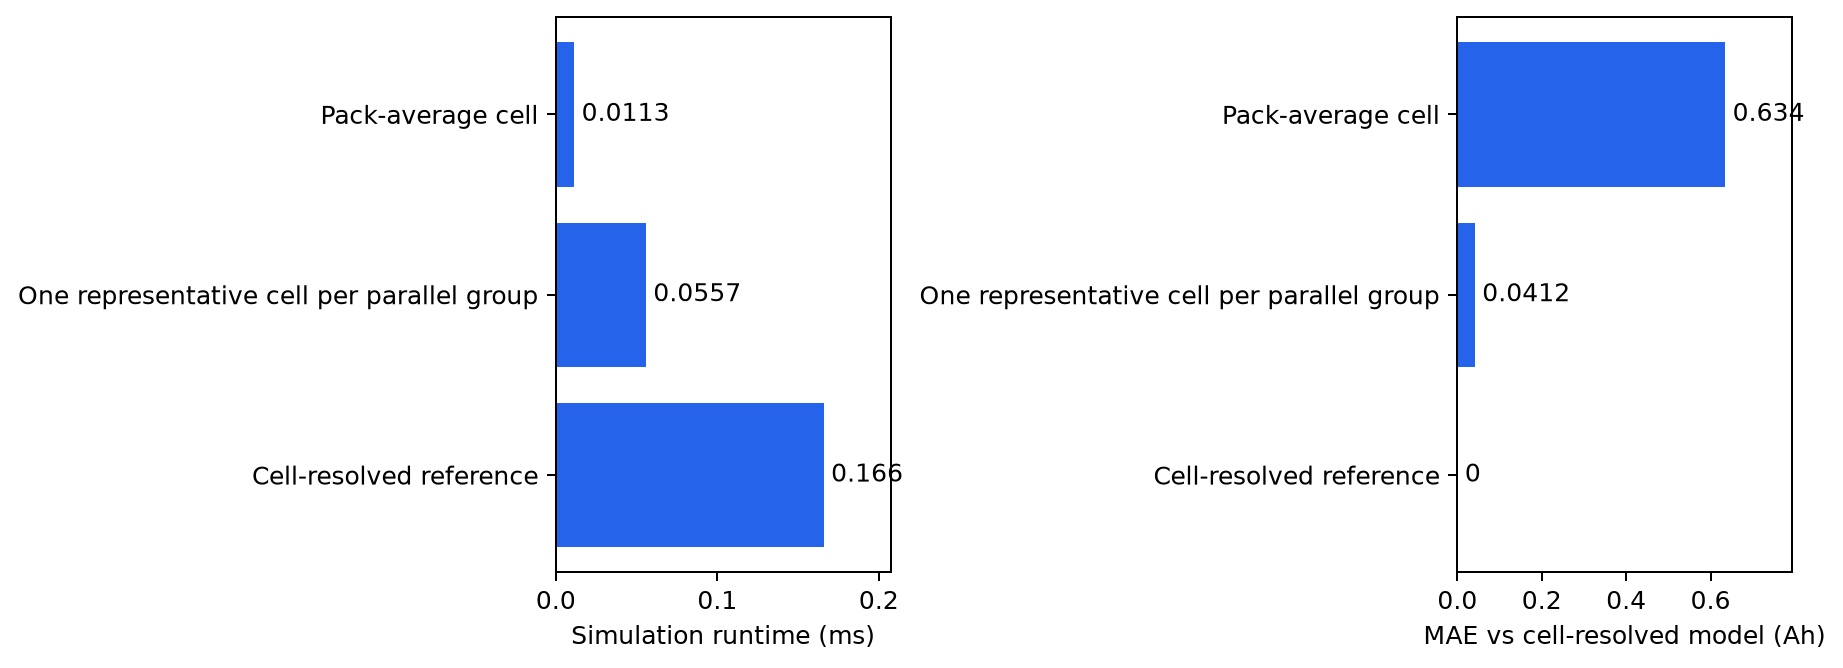

In [ ]:
output = task5 / "results"
save_plots(traces, timing, output)
for name in ("pack_capacity_scenarios.png", "scaling_accuracy_runtime.png"):
    display(Image(filename=str(output / name)))

I measure simulation runtime on the current machine. The error shows how closely each approximation matches the cell-resolved model.

Key findings from my run
I compare the final usable capacity across scenarios, then check how much runtime drops when I use fewer representative cells.

- Using the rates fitted to the available cell runs, after 100 cycles the uniform pack has 1.77 Ah of accessible capacity and the combined scenario has 0.69 Ah.
- The successive changes in end-of-horizon pack capacity are -0.53 Ah for cell variation, -0.52 Ah for the temperature gradient, and -0.03 Ah for residual SOC mismatch. Each change is relative to the previous scenario.
- The grouped model has 0.041 Ah mean absolute error against the cell-resolved simulation. The pack-average model has 0.634 Ah. Median runtimes are 0.011, 0.056, and 0.166 ms, respectively, for pack-average, grouped, and cell-resolved simulations.

#### Limits of my data
- I have two cell runs under different conditions, so I cannot separate manufacturing variation from test-condition effects.
- I lack module or pack capacity tests, temperature profiles, and balancing logs to calibrate and validate the model.
- My model simplifies current sharing, voltage limits, heat transfer, and late-life fade. I use the results to compare scenarios.

#### Trade-offs between accuracy and computational scalability.

- **Pack-average model (1 unit):** It was the fastest, but averaging across the pack hid weak groups and overestimated final capacity at **1.16 Ah** versus **0.69 Ah** in the cell-resolved simulation.
- **Parallel-group model (32 units):** It preserved differences between groups, ran **2.6× faster** than the cell-resolved model, and had a mean absolute difference of **0.041 Ah** across the simulated cycles.
- **Cell-resolved model (128 units):** It captured individual cell differences and took the longest to run, with one unit to track for every cell added to the pack.
- **Trade-off:** The parallel-group model offered the best balance for this simulated pack by tracking one-quarter as many units as the cell-resolved model while closely matching its capacity estimates.